In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical

# Load your dataset (adjust the file path)
data_df = pd.read_csv('imu_posture_samples.csv')

# Separate features (Ax, Ay, Az) and labels (position classes)
X = data_df[['Ax', 'Ay', 'Az']]
y = data_df['labels']

X += 0.1 * np.random.randn(*X.shape)
y = y - 1 # to transform the labels starting from '1' to '0' as frameworks like tensor flow accept labels starting from '0'

In [2]:
# Get the number of unique classes in your labels
#num_classes = len(np.unique(y))

# One-hot encode the labels with the correct number of classes
y = to_categorical(y, num_classes=5)

#y = to_categorical(y)

In [3]:
# Split data into training, validation, and test sets
train_ratio = 0.7  # Adjust the ratio as needed
val_ratio = 0.15
test_ratio = 0.15

# Split the data into training and validation sets
#X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.5, random_state=42)

# First, split into train and temp sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=(1 - train_ratio), random_state=42)

# Then, split the temp set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=test_ratio / (test_ratio + val_ratio), random_state=42)


In [4]:
import tensorflow as tf
from tensorflow import keras

# Define the neural network architecture
model_relu = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(3,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(5, activation='softmax')  # 5 classes for 'supine' to 'unknown posture'
])

# Compile the model
model_relu.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Display a summary of the model's architecture
model_relu.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               512       
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 5)                 165       
                                                                 
Total params: 11013 (43.02 KB)
Trainable params: 11013 (43.02 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [5]:
# Define the neural network architecture with Sigmoid activation
model_sigmoid = keras.Sequential([
    keras.layers.Dense(128, activation='sigmoid', input_shape=(3,)),
    keras.layers.Dense(64, activation='sigmoid'),
    keras.layers.Dense(32, activation='sigmoid'),
    keras.layers.Dense(5, activation='softmax')  # 5 classes for 'supine' to 'unknown posture'
])

# Compile the model with Sigmoid activation
model_sigmoid.compile(optimizer='adam',
                      loss='categorical_crossentropy',
                      metrics=['accuracy'])

# Display a summary of the Sigmoid model's architecture
model_sigmoid.summary()



Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 128)               512       
                                                                 
 dense_5 (Dense)             (None, 64)                8256      
                                                                 
 dense_6 (Dense)             (None, 32)                2080      
                                                                 
 dense_7 (Dense)             (None, 5)                 165       
                                                                 
Total params: 11013 (43.02 KB)
Trainable params: 11013 (43.02 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [6]:
# Define the neural network architecture with Tanh activation
model_tanh = keras.Sequential([
    keras.layers.Dense(128, activation='tanh', input_shape=(3,)),
    keras.layers.Dense(64, activation='tanh'),
    keras.layers.Dense(32, activation='tanh'),
    keras.layers.Dense(5, activation='softmax')  # 5 classes for 'supine' to 'unknown posture'
])

# Compile the model with Tanh activation
model_tanh.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])

# Display a summary of the Tanh model's architecture
model_tanh.summary()


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_8 (Dense)             (None, 128)               512       
                                                                 
 dense_9 (Dense)             (None, 64)                8256      
                                                                 
 dense_10 (Dense)            (None, 32)                2080      
                                                                 
 dense_11 (Dense)            (None, 5)                 165       
                                                                 
Total params: 11013 (43.02 KB)
Trainable params: 11013 (43.02 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [7]:
# Train the model
history_relu = model_relu.fit(X_train, y_train, epochs=500, batch_size=32, validation_data=(X_val, y_val))
history_sigmoid = model_sigmoid.fit(X_train, y_train, epochs=500, batch_size=32, validation_data=(X_val, y_val))
history_tanh = model_tanh.fit(X_train, y_train, epochs=500, batch_size=32, validation_data=(X_val, y_val))


Epoch 1/500
82/82 [==============================] - 4s 20ms/step - loss: 1.0376 - accuracy: 0.7270 - val_loss: 0.5012 - val_accuracy: 0.8321
Epoch 2/500
82/82 [==============================] - 0s 3ms/step - loss: 0.3787 - accuracy: 0.8642 - val_loss: 0.2837 - val_accuracy: 0.9018
Epoch 3/500
82/82 [==============================] - 1s 6ms/step - loss: 0.3011 - accuracy: 0.8937 - val_loss: 0.2437 - val_accuracy: 0.9232
Epoch 4/500
82/82 [==============================] - 0s 4ms/step - loss: 0.2719 - accuracy: 0.8948 - val_loss: 0.2160 - val_accuracy: 0.9321
Epoch 5/500
82/82 [==============================] - 0s 6ms/step - loss: 0.2622 - accuracy: 0.9006 - val_loss: 0.2271 - val_accuracy: 0.9321
Epoch 6/500
82/82 [==============================] - 0s 4ms/step - loss: 0.2635 - accuracy: 0.9025 - val_loss: 0.2131 - val_accuracy: 0.9196
Epoch 7/500
82/82 [==============================] - 0s 5ms/step - loss: 0.2546 - accuracy: 0.9002 - val_loss: 0.2241 - val_accuracy: 0.9161
Epoch 8/500


18/18 [==============================] - 0s 1ms/step - loss: 0.4046 - accuracy: 0.8948
ReLU Model - Test Accuracy: 0.8770053386688232
Sigmoid Model - Test Accuracy: 0.8859180212020874
Tanh Model - Test Accuracy: 0.8948306441307068


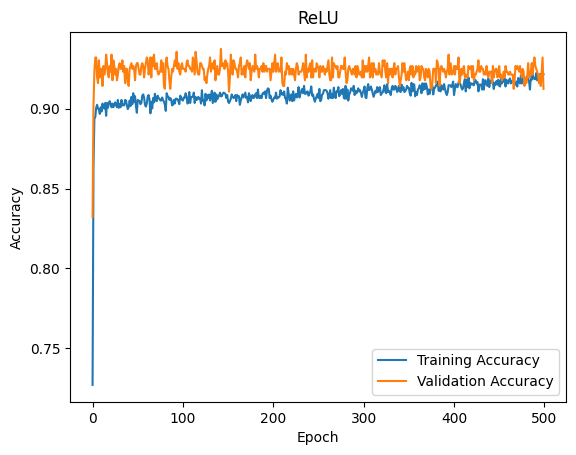

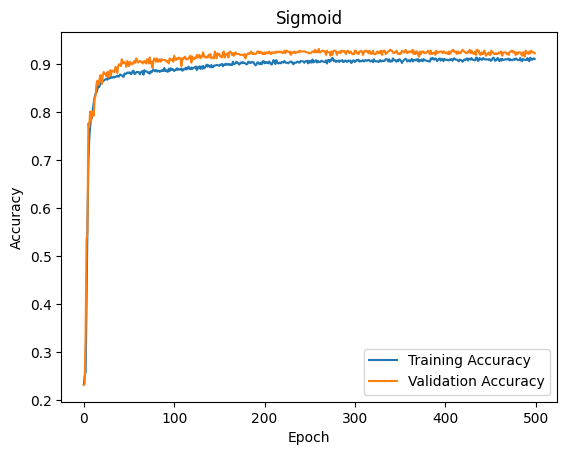

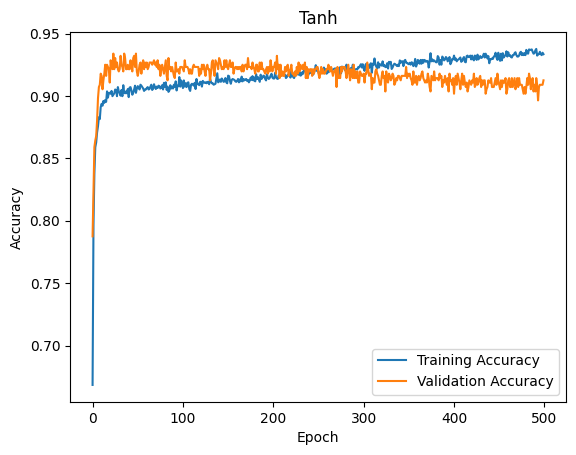

In [8]:
# Evaluate the model on the test set

score_relu = model_relu.evaluate(X_test, y_test)
score_sigmoid = model_sigmoid.evaluate(X_test, y_test)
score_tanh = model_tanh.evaluate(X_test, y_test)

#print("ReLU Model - Test Loss:", score_relu[0])
print("ReLU Model - Test Accuracy:", score_relu[1])

#print("Sigmoid Model - Test Loss:", score_sigmoid[0])
print("Sigmoid Model - Test Accuracy:", score_sigmoid[1])

#print("Tanh Model - Test Loss:", score_tanh[0])
print("Tanh Model - Test Accuracy:", score_tanh[1])

#Visualize training and validation metrics
import matplotlib.pyplot as plt

plt.plot(history_relu.history['accuracy'], label='Training Accuracy')
plt.plot(history_relu.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('ReLU')
plt.legend()
plt.show()

plt.plot(history_sigmoid.history['accuracy'], label='Training Accuracy')
plt.plot(history_sigmoid.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Sigmoid')
plt.legend()
plt.show()

plt.plot(history_tanh.history['accuracy'], label='Training Accuracy')
plt.plot(history_tanh.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Tanh')
plt.legend()
plt.show()
